# Assignment 2 - Question 3: Logistic regression from scratch

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('screen_train.csv')
test = pd.read_csv('screen_test.csv')

X_train = train[['marker1', 'marker2']].values
t_train = train['disease'].values
X_test = test[['marker1', 'marker2']].values
t_test = test['disease'].values

print(train.shape, test.shape)
print('Disease rate (train):', t_train.mean())

(600, 3) (400, 3)
Disease rate (train): 0.1


## (a) Train

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(X, w):
    # w[0] is the bias, w[1] and w[2] are the marker weights
    return sigmoid(w[0] + X @ w[1:])

def cross_entropy(y, t):
    return np.mean(-t * np.log(y) - (1 - t) * np.log(1 - y))

def train_logistic(X, t, alpha=0.1, iterations=5000):
    N = len(t)
    w = np.zeros(3)
    losses = []
    for i in range(iterations):
        y = predict(X, w)
        losses.append(cross_entropy(y, t))
        error = y - t
        w[0] = w[0] - (alpha / N) * np.sum(error)
        w[1:] = w[1:] - (alpha / N) * (X.T @ error)
    return w, losses

w, losses = train_logistic(X_train, t_train)

print('First loss:', round(losses[0], 4), '(ln 2 =', round(np.log(2), 4), ')')
print('Final loss:', round(losses[-1], 4))
print('Final weights: w0 = %.4f, w1 = %.4f, w2 = %.4f' % (w[0], w[1], w[2]))

First loss: 0.6931 (ln 2 = 0.6931 )
Final loss: 0.1934
Final weights: w0 = -4.0076, w1 = 1.5845, w2 = 1.1185


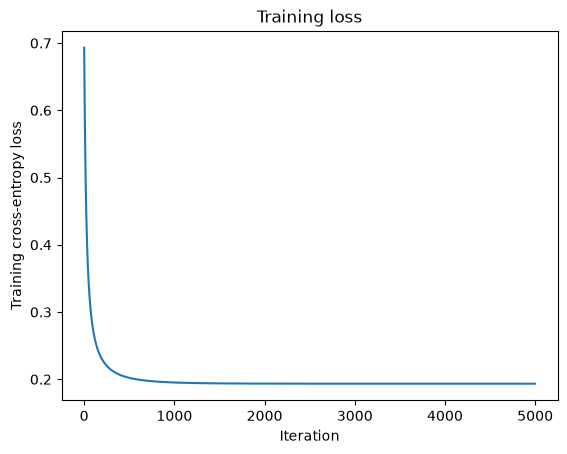

In [3]:
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Training cross-entropy loss')
plt.title('Training loss')
plt.show()

## (b) Evaluate at threshold 0.5

In [4]:
def evaluate(y_prob, t, threshold):
    pred = (y_prob >= threshold).astype(int)
    TP = np.sum((pred == 1) & (t == 1))
    FN = np.sum((pred == 0) & (t == 1))
    FP = np.sum((pred == 1) & (t == 0))
    TN = np.sum((pred == 0) & (t == 0))
    return TP, FN, FP, TN

y_test = predict(X_test, w)
TP, FN, FP, TN = evaluate(y_test, t_test, 0.5)

accuracy = (TP + TN) / len(t_test)
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print('TP =', TP, ' FN =', FN, ' FP =', FP, ' TN =', TN)
print('Accuracy:    %.4f' % accuracy)
print('Sensitivity: %.4f' % sensitivity)
print('Specificity: %.4f' % specificity)

# Baseline: predict "no disease" for everyone
baseline_accuracy = np.mean(t_test == 0)
print('Baseline (always no disease) accuracy: %.4f' % baseline_accuracy)

TP = 17  FN = 23  FP = 6  TN = 354
Accuracy:    0.9275
Sensitivity: 0.4250
Specificity: 0.9833
Baseline (always no disease) accuracy: 0.9000


**Comparison.** The model's accuracy (0.9275) is only a little higher than the 0.9000 a useless model gets by always predicting "no disease". Only 10% of patients are sick, so accuracy is dominated by the healthy majority. The model still misses 23 of the 40 sick patients (sensitivity 0.425), so on an imbalanced problem like this, accuracy is misleading and sensitivity and specificity are better measures.

## (c) ROC curve and AUC

AUC: 0.8865


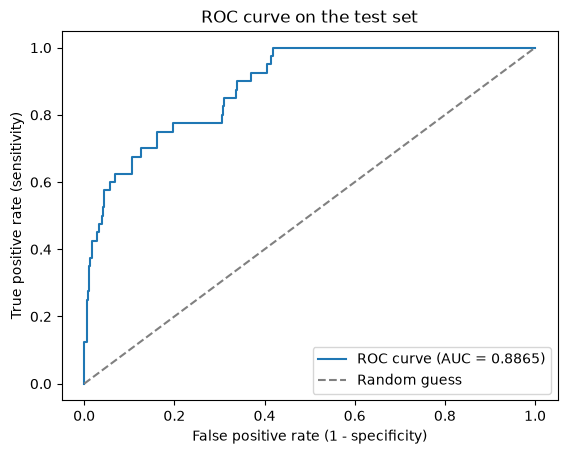

In [5]:
fpr_list = [0.0, 1.0]
tpr_list = [0.0, 1.0]
for threshold in np.unique(y_test):
    TP, FN, FP, TN = evaluate(y_test, t_test, threshold)
    fpr_list.append(FP / (FP + TN))
    tpr_list.append(TP / (TP + FN))

# Sort by FPR (then TPR, so ties go up the curve)
points = sorted(zip(fpr_list, tpr_list))
fpr = [p[0] for p in points]
tpr = [p[1] for p in points]

auc = 0
for i in range(len(fpr) - 1):
    auc += (fpr[i + 1] - fpr[i]) * (tpr[i] + tpr[i + 1]) / 2

print('AUC: %.4f' % auc)

plt.plot(fpr, tpr, label='ROC curve (AUC = %.4f)' % auc)
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random guess')
plt.xlabel('False positive rate (1 - specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

## (d) Threshold 0.1

In [6]:
TP, FN, FP, TN = evaluate(y_test, t_test, 0.1)
print('TP =', TP, ' FN =', FN, ' FP =', FP, ' TN =', TN)
print('Sensitivity: %.4f' % (TP / (TP + FN)))
print('Specificity: %.4f' % (TN / (TN + FP)))

TP = 28  FN = 12  FP = 55  TN = 305
Sensitivity: 0.7000
Specificity: 0.8472


**What changed.** Lowering the threshold to 0.1 raised sensitivity from 0.4250 to 0.7000 (28 of 40 sick patients caught instead of 17), but specificity dropped from 0.9833 to 0.8472 because there are more false alarms (55 instead of 6). A hospital would prefer 0.1 for a screening test where missing a sick patient is much worse than sending a healthy patient for a follow-up test.